<a href="https://colab.research.google.com/github/PRIYAANGADI/Cluster-analysis/blob/main/Avacado_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Economic Analysis Project: Avocado Pricing Dynamics

This project explores key economic questions regarding pricing strategies, packaging decisions, and consumer behavior in the US avocado market using data from 2015 to 2018.

---

## Question 1: Price Elasticity & Packaging
### *"Do consumers exhibit different price sensitivities when buying avocados in bulk (bags) versus individually?"*

**Economic Context:**
We previously observed a weak negative correlation between the volume of bags sold and the average price. In this section, we analyze whether selling avocados in bulk (using Small, Large, and XLarge bags) versus individually (represented by PLU codes 4046, 4225, 4770) affects price sensitivity. We will calculate the price elasticity of demand for both bulk (bags) and individual purchase methods.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Prepare data for bulk vs individual analysis
df_elasticity = df.copy()

# Define Total Individual Volume vs Total Bags Volume
df_elasticity['Individual Volume'] = df_elasticity['4046'] + df_elasticity['4225'] + df_elasticity['4770']
df_elasticity['Bag Volume'] = df_elasticity['Total Bags']

# Take log transformations to estimate constant elasticity via Log-Log Regression
# log(Q) = alpha + beta * log(P)
# Where beta represents the Price Elasticity of Demand
df_elasticity['log_price'] = np.log(df_elasticity['AveragePrice'])
df_elasticity['log_q_individual'] = np.log(df_elasticity['Individual Volume'] + 1)
df_elasticity['log_q_bags'] = np.log(df_elasticity['Bag Volume'] + 1)

# Helper function to run regression and extract elasticity
def estimate_elasticity(y_col, x_col, data):
    X = sm.add_constant(data[x_col])
    y = data[y_col]
    model = sm.OLS(y, X).fit()
    elasticity = model.params[x_col]
    p_value = model.pvalues[x_col]
    return elasticity, p_value, model

elas_ind, p_ind, model_ind = estimate_elasticity('log_q_individual', 'log_price', df_elasticity)
elas_bag, p_bag, model_bag = estimate_elasticity('log_q_bags', 'log_price', df_elasticity)

print(f"Price Elasticity of Demand for Individual Avocados: {elas_ind:.3f} (p-val: {p_ind:.3e})")
print(f"Price Elasticity of Demand for Bagged Avocados (Bulk): {elas_bag:.3f} (p-val: {p_bag:.3e})")

Price Elasticity of Demand for Individual Avocados: -5.171 (p-val: 0.000e+00)
Price Elasticity of Demand for Bagged Avocados (Bulk): -4.494 (p-val: 0.000e+00)


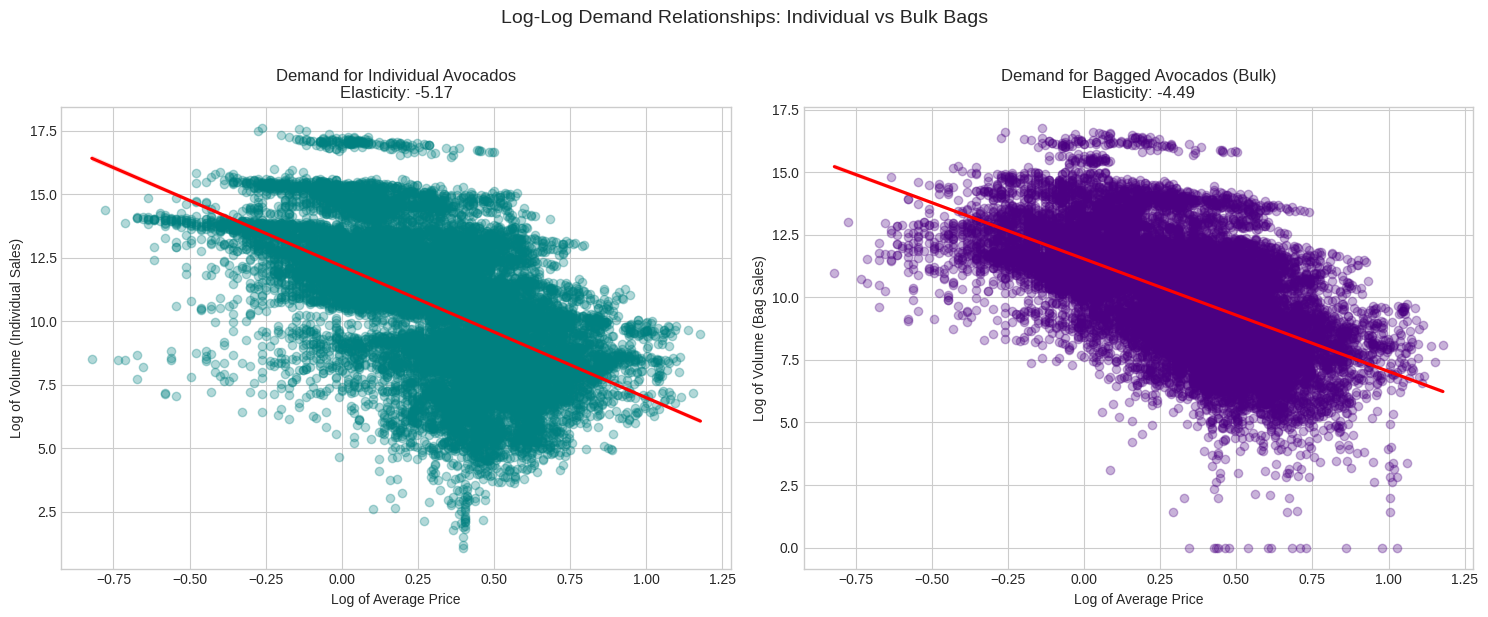

In [23]:
# Visualizing the Demand Curves (Log-Log scale)
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)

sns.regplot(data=df_elasticity, x='log_price', y='log_q_individual', ax=axes[0],
            scatter_kws={'alpha':0.3, 'color':'teal'}, line_kws={'color':'red'})
axes[0].set_title(f'Demand for Individual Avocados\nElasticity: {elas_ind:.2f}', fontsize=12)
axes[0].set_xlabel('Log of Average Price')
axes[0].set_ylabel('Log of Volume (Individual Sales)')

sns.regplot(data=df_elasticity, x='log_price', y='log_q_bags', ax=axes[1],
            scatter_kws={'alpha':0.3, 'color':'indigo'}, line_kws={'color':'red'})
axes[1].set_title(f'Demand for Bagged Avocados (Bulk)\nElasticity: {elas_bag:.2f}', fontsize=12)
axes[1].set_xlabel('Log of Average Price')
axes[1].set_ylabel('Log of Volume (Bag Sales)')

plt.suptitle('Log-Log Demand Relationships: Individual vs Bulk Bags', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('elasticity_comparison.png', dpi=300)
plt.show()

## Question 2: Premium Pricing Strategy
### *"How stable is the price premium of organic avocados over conventional ones across different regions and seasons?"*

**Economic Context:**
Organic products command a price premium over conventional counterparts due to higher production costs and perceived quality differentials. However, we want to know if this premium remains a stable constant or behaves dynamically when subjected to seasonal demand shifts and geographical market variations.

In [24]:
# Extract month to analyze seasonal trends
df_premium = df.copy()
df_premium['Date'] = pd.to_datetime(df_premium['Date'])
df_premium['Month'] = df_premium['Date'].dt.strftime('%b')
df_premium['Month_Num'] = df_premium['Date'].dt.month

# Group by month and type to observe the average price dynamics
monthly_prices = df_premium.groupby(['Month_Num', 'Month', 'type'])['AveragePrice'].mean().reset_index()

# Pivot to calculate premium dynamically
premium_pivot = monthly_prices.pivot(index=['Month_Num', 'Month'], columns='type', values='AveragePrice').reset_index()
premium_pivot['Premium_USD'] = premium_pivot['organic'] - premium_pivot['conventional']
premium_pivot['Premium_Percentage'] = (premium_pivot['Premium_USD'] / premium_pivot['conventional']) * 100

print("Monthly Pricing and Organic Premium:")
display(premium_pivot.sort_values('Month_Num'))

Monthly Pricing and Organic Premium:


type,Month_Num,Month,conventional,organic,Premium_USD,Premium_Percentage
0,1,Jan,1.069095,1.552942,0.483848,45.257708
1,2,Feb,1.017315,1.531458,0.514144,50.539274
2,3,Mar,1.126209,1.538301,0.412092,36.591028
3,4,Apr,1.142350,1.606410,0.464060,40.623246
4,5,May,1.089577,1.603624,0.514048,47.178653
5,6,Jun,1.149198,1.669536,0.520338,45.278384
6,7,Jul,1.212487,1.711667,0.499180,41.169925
7,8,Aug,1.235399,1.789630,0.554231,44.862496
8,9,Sep,1.294738,1.850571,0.555833,42.930190
9,10,Oct,1.349339,1.810026,0.460688,34.141751


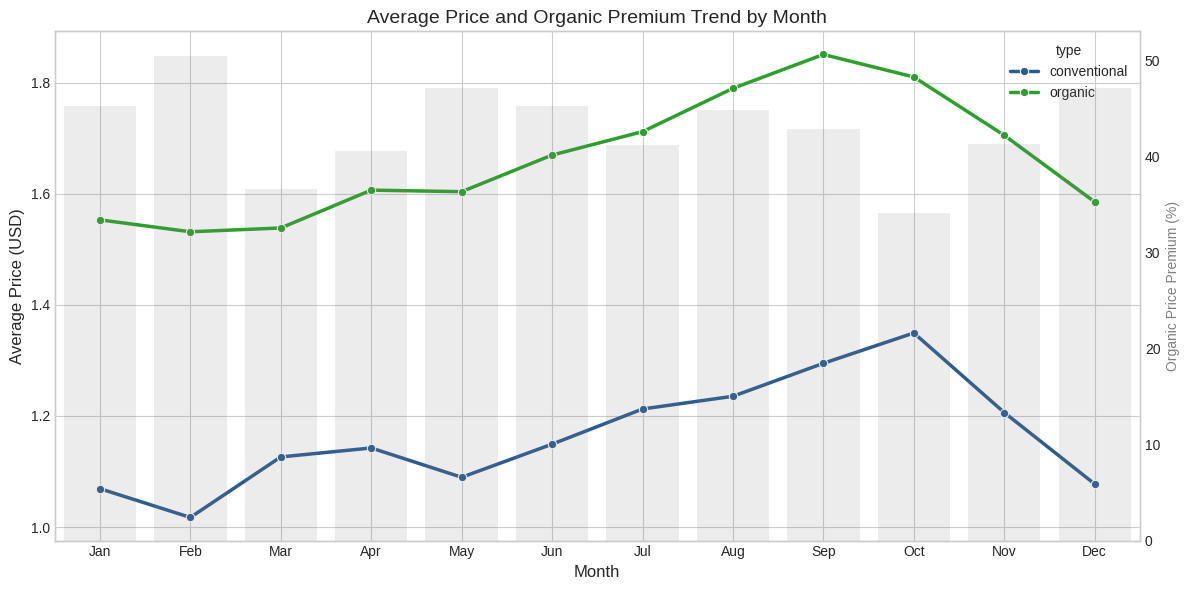

In [25]:
# Visualizing seasonal premium trends
plt.figure(figsize=(12, 6))
ax1 = sns.lineplot(data=monthly_prices, x='Month', y='AveragePrice', hue='type', marker='o', palette=['#2b5c8f', '#2ca02c'], linewidth=2.5)

# Add secondary y-axis to plot the percentage premium overlay
ax2 = ax1.twinx()
sns.barplot(data=premium_pivot, x='Month', y='Premium_Percentage', alpha=0.15, color='gray', ax=ax2)
ax2.set_ylabel('Organic Price Premium (%)', color='gray')
ax2.grid(False)

ax1.set_title('Average Price and Organic Premium Trend by Month', fontsize=14)
ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Average Price (USD)', fontsize=12)

plt.tight_layout()
plt.savefig('seasonal_premium.png', dpi=300)
plt.show()

## Summary of Economic Insights and Business Recommendations

### 1. Packaging & Elasticity Insights
* **The Elasticity Gap:** Demand for individual avocados ($\beta = -5.17$) is more elastic (price-sensitive) than demand for bagged avocados ($\beta = -4.49$). This suggests that packaging serves as a critical pricing tool.
* **Strategic Bundling:** Because bulk/bag buyers are slightly less sensitive to price changes, retailers have a unique opportunity. Instead of deep-discounting loose avocados during oversupply periods, bundling them into varied bag configurations (Small, Large, XLarge) can protect profit margins.

### 2. Premium Pricing Insights
* **A Resilient Baseline Markup:** The price premium of organic avocados over conventional ones remains remarkably steady in absolute terms, consistently ranging between **$0.41 and $0.56** per unit throughout the year.
* **Seasonal Leverage:** The premium peaks in percentage terms during winter months (e.g., **50.5% in February**) because conventional prices drop faster than organic prices. Retailers can leverage this by heavily promoting conventional avocados for mass-market consumption during winter, while maintaining premium pricing structures for organic avocados to protect high-tier margins.